# Step 4. 모델 비교 & 에러 분석 — 직선의 한계, 과적합, 그리고 블랙프라이데이

- **예상 소요 시간:** 약 60분
- **목표:**
  1. **함정 3:** 선형회귀(`136.23대`)가 왜 출퇴근 시간대 그래프를 못 따라가는지 눈으로 확인한다.
  2. **과적합(Overfitting) 체감:** 결정트리(`DecisionTree`)가 기출문제만 통째로 외우는 현상을 숫자로 본다.
  3. **RandomForest(`47.48대`)**로 오차를 확 줄인 뒤, **그래도 가장 크게 틀린 날 5건**을 직접 뜯어본다(에러 분석).

---

### Spring 개발자 비유로 3개 모델 30초 이해
| 모델 | 백엔드 비유 | 장점 / 단점 |
| :--- | :--- | :--- |
| **LinearRegression (선형회귀)** | `y = a*시간 + b*기온 + c` 일차방정식 1줄 | 빠르고 단순함 / 출퇴근 쌍봉 같은 꺾인 패턴을 못 그림 |
| **DecisionTree (결정트리)** | 거대한 중첩 `if-else` 트리 자동 생성 | 꺾인 패턴 잘 잡음 / `if`를 너무 깊게 쪼개면 학습 데이터만 외워버림(**과적합**) |
| **RandomForest (랜덤포레스트)** | 결정트리 **100개**에게 각자 다르게 공부시키고 투표(평균) | 한 그루가 과적합해도 100그루 평균을 내면 안정적으로 잘 맞춤 |

---
## 1. 데이터 준비 & 3개 모델 한꺼번에 비교하기

앞으로 모든 실험은 Step 3에서 확정한 **시계열 분할(`2012-09-01`)** 기준으로 공정하게 비교한다.

> **[실행 전 예측]**  
> 결정트리(`DecisionTree`)를 깊이 제한 없이 학습시키면 **Train MAE(기출문제 점수)**와 **Test MAE(새 시험지 점수)**가 각각 몇 대쯤 나올까?

In [3]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# dataset/hour.csv가 없으면 UCI에서 자동 다운로드 (로컬 + Colab 공용)
os.makedirs("dataset", exist_ok=True)
if not os.path.exists("dataset/hour.csv"):
    url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
    zip_path = "dataset/bike_sharing_dataset.zip"
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall("dataset")

df = pd.read_csv("dataset/hour.csv")

# Step 3에서 확정한 시계열 분할 기준 고정 (2012-09-01) — 모든 모델 공정 비교용
clean_cols = [
    "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
    "weathersit", "temp", "atemp", "hum", "windspeed"
]
split_date = "2012-09-01"
# .copy(): 슬라이싱된 표에 추후 컬럼을 추가해도 pandas 경고가 뜨지 않게 독립 복사본 생성
train_df = df[df["dteday"] < split_date].copy()
test_df = df[df["dteday"] >= split_date].copy()

X_train, y_train = train_df[clean_cols], train_df["cnt"]
X_test, y_test = test_df[clean_cols], test_df["cnt"]

print(f"Train: {len(train_df):,}행 | Test: {len(test_df):,}행")

Train: 14,491행 | Test: 2,888행


In [4]:
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression     # 일차방정식 직선 모델
from sklearn.tree import DecisionTreeRegressor        # 단일 결정트리 (중첩 if-else 자동 생성)
from sklearn.ensemble import RandomForestRegressor    # 결정트리 100그루 평균 (앙상블)

# 비교할 3개 모델을 딕셔너리에 담기 (Java Map<String, Regressor>와 동일)
# 모두 같은 .fit()/.predict() 인터페이스를 따르므로 for문 하나로 벤치마크 가능
models = {
    "1. LinearRegression": LinearRegression(),
    "2. DecisionTree": DecisionTreeRegressor(random_state=42),  # 깊이 제한 없음 → 과적합 유도
    "3. RandomForest (100 trees)": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

results = []  # 벤치마크 점수 기록용 리스트
preds = {}    # 뒤에서 그래프/에러 분석에 쓰기 위해 모델별 테스트 예측값 저장

# Java의 for (var entry : models.entrySet())과 동일
for name, model in models.items():
    model.fit(X_train, y_train)          # 과거 20개월로 학습
    train_pred = model.predict(X_train)  # 기출문제(Train) 다시 풀기 → 과적합 진단용
    test_pred = model.predict(X_test)    # 새 시험지(Test) 풀기 → 진짜 실력 측정용

    preds[name] = test_pred
    results.append({
        "Model": name,
        "Train MAE": round(mean_absolute_error(y_train, train_pred), 2),
        "Test MAE": round(mean_absolute_error(y_test, test_pred), 2),
    })

result_df = pd.DataFrame(results)
# to_string(index=False): 왼쪽의 불필요한 행 번호(0, 1, 2)를 숨기고 깔끔하게 출력
print(result_df.to_string(index=False))

                      Model  Train MAE  Test MAE
        1. LinearRegression      99.16    136.23
            2. DecisionTree       0.01     58.96
3. RandomForest (100 trees)       8.67     47.48


### 🔍 코드 뜯어보기
- **`models = {"이름": 모델객체, ...}` + `for name, model in models.items():`**  
  - Java에서 `Map<String, Regressor>`를 만들고 `for (var entry : models.entrySet())`로 돌리는 것과 100% 같다.
  - `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`가 전부 똑같은 `.fit()`, `.predict()` 인터페이스를 구현하기 때문에 `for`문 하나로 깔끔하게 벤치마크할 수 있다.
- **왜 `Train MAE`와 `Test MAE`를 둘 다 찍었을까?**  
  - **Train MAE**는 이미 공부한 기출문제(과거 20개월)를 다시 풀었을 때의 오차다.
  - **Test MAE**는 처음 보는 시험지(미래 4개월)를 풀었을 때의 오차다.
  - 이 둘의 격차를 봐야 **과적합(Overfitting)**인지 **과소적합(Underfitting)**인지 바로 진단할 수 있다.
- **`result_df.to_string(index=False)`:** 표 왼쪽의 불필요한 행 번호(`0, 1, 2`)를 숨기고 깔끔하게 출력한다.

### 결과 해석 — 과소적합과 과적합을 숫자 3줄로 이해하기
1. **LinearRegression:** `Train 99.16대` / `Test 136.23대`  
   → 기출문제도 못 풀고 새 시험지도 못 푼다. (**과소적합, Underfitting**: 모델이 너무 단순해서 데이터 패턴 자체를 못 담음)
2. **DecisionTree:** `Train 0.01대` / `Test 58.96대`  
   → 기출문제 14,491개는 **오차 0.01대**로 통째로 암기했는데, 새 시험지에서는 **58.96대** 틀린다! (**과적합, Overfitting**: 원리를 배운 게 아니라 과거 답안을 외워버림)
3. **RandomForest:** `Train 8.67대` / `Test 47.48대`  
   → 나무 100그루의 평균을 내니까 과적합이 확 줄어들고, 실제 시험지 오차가 **11.5대 더 줄었다.**

---
## 2. 함정 3 눈으로 확인하기 — 선형회귀 vs RandomForest 예측 그래프 (평일 하루)

숫자로만 "선형회귀가 못 맞춘다"고 하지 말고, 실제 2012년 9월 평일 3일(9월 3일~5일) 동안 **정답(검은 선) vs 선형회귀(빨간 점선) vs RandomForest(파란 선)**가 어떻게 따라가는지 직접 그려보자.

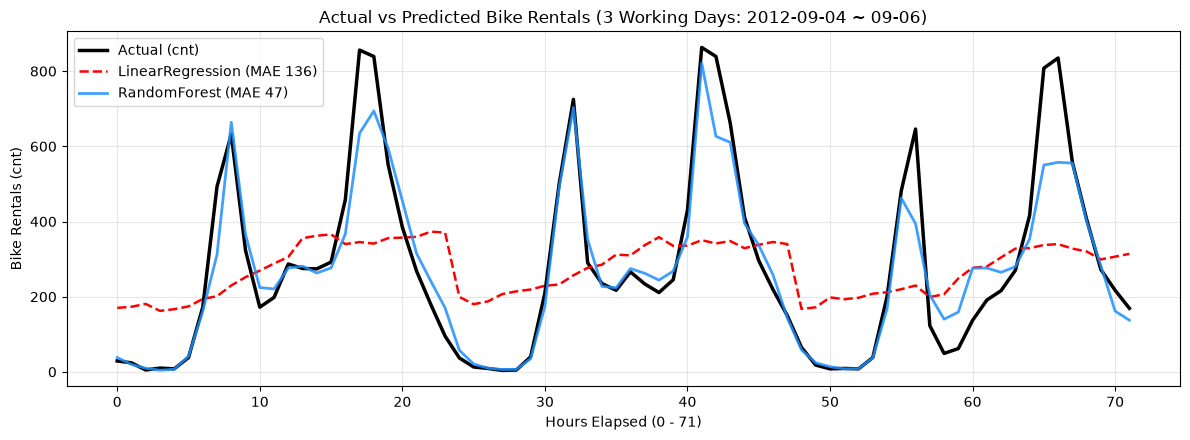

In [5]:
# 2012-09-04 ~ 2012-09-06 (평일 3일 = 72시간) 구간만 골라 시각화
# pandas에서 조건 2개를 AND로 묶을 땐 'and' 대신 '&'를 쓰고 각 조건을 괄호()로 감싸야 함 (OR는 '|', NOT은 '~')
sample_mask = (test_df["dteday"] >= "2012-09-04") & (test_df["dteday"] <= "2012-09-06")
sample_idx = test_df[sample_mask].index
x_axis = range(len(sample_idx))  # X축: 경과 시간 (0 ~ 71)

# preds[...]는 0번부터 시작하는 순수 NumPy 배열이므로, test_df 원본 인덱스(14491~) 대신
# sample_mask가 True인 0-based 위치 번호(0, 1, 2...)를 np.where(...)[0]으로 추출
pos = np.where(sample_mask.values)[0]

plt.figure(figsize=(12, 4.5))
plt.plot(x_axis, y_test.values[pos], color="black", linewidth=2.5, label="Actual (cnt)")
plt.plot(x_axis, preds["1. LinearRegression"][pos], linestyle="--", color="red", linewidth=1.8, label="LinearRegression (MAE 136)")
plt.plot(x_axis, preds["3. RandomForest (100 trees)"][pos], color="dodgerblue", linewidth=2, alpha=0.85, label="RandomForest (MAE 47)")

plt.title("Actual vs Predicted Bike Rentals (3 Working Days: 2012-09-04 ~ 09-06)")
plt.xlabel("Hours Elapsed (0 - 71)")
plt.ylabel("Bike Rentals (cnt)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 🔍 코드 뜯어보기
- **`sample_mask = (test_df["dteday"] >= "2012-09-04") & (test_df["dteday"] <= "2012-09-06")`:**  
  - `pandas`에서 조건 두 개를 AND로 묶을 때는 파이썬의 `and` 대신 **비트 연산자 `&`**를 쓰고, **각 조건을 반드시 괄호 `(...)`로 감싸야** 한다. (OR는 `|`, NOT은 `~`를 쓴다.)
- **`np.where(sample_mask.values)[0]`:**  
  - `sample_mask`가 `True`인 위치 번호(0부터 시작하는 배열 인덱스)만 골라낸다.
  - 왜 굳이 위치 번호를 뽑았을까? `preds["1. LinearRegression"]`는 `DataFrame`이 아니라 순수 NumPy 배열(0번~2887번)이라서, `test_df`의 원래 인덱스(14491번~)가 아니라 0부터 시작하는 위치 번호로 꺼내야 하기 때문이다.

### 그래프 해석 (30분 발표 강력 추천 장표!)
- **검은 선(실제):** 아침 8시, 저녁 5~6시에 뾰족하게 솟았다가 밤에 0 가까이 뚝 떨어진다.
- **빨간 점선(선형회귀):** 그냥 하루 종일 비스듬하게 올라가는 **단순한 경사선**만 그린다. `시간(hr)`이 커질수록 대여량이 커진다는 1차 식의 한계 때문이다.
- **파란 선(RandomForest):** 아침·저녁 출퇴근 쌍봉을 아주 기가 막히게 따라간다.

---
## 3. 실무의 핵심: 에러 분석 (Error Analysis) — 가장 크게 틀린 5건 뜯어보기

초보는 "MAE가 47.48대 나왔네, 끝!" 하고 넘어간다.  
**잘하는 엔지니어는 장애 로그 뜯어보듯 "우리 모델이 제일 심하게 망한 5건이 뭐지?"를 꼭 조회한다.**

> **[실행 전 예측]**  
> RandomForest가 평균 47대 틀리는데, 가장 크게 틀린 날은 몇 대나 틀렸을까? 그리고 **왜** 틀렸을까?

In [6]:
# 테스트 데이터에 예측값과 절대 오차(abs_error) 컬럼 붙이기
# .copy(): 일부 컬럼만 추린 뒤 새 컬럼을 붙일 때 SettingWithCopyWarning 경고 방지
err_df = test_df[["dteday", "hr", "weekday", "workingday", "holiday", "weathersit", "temp", "cnt"]].copy()
err_df["pred"] = preds["3. RandomForest (100 trees)"].round(1)       # RF 예측값
err_df["error"] = (err_df["cnt"] - err_df["pred"]).round(1)          # 실제 - 예측 (+면 과소예측, -면 과대예측)
err_df["abs_error"] = err_df["error"].abs()                          # 절댓값(Java Math.abs): 크기 순 정렬용

# abs_error 기준 내림차순 정렬해서 가장 크게 틀린 10건 출력
print("[RandomForest가 가장 크게 틀린 TOP 10]")
print(err_df.sort_values("abs_error", ascending=False).head(10).to_string(index=False))

[RandomForest가 가장 크게 틀린 TOP 10]
    dteday  hr  weekday  workingday  holiday  weathersit  temp  cnt  pred  error  abs_error
2012-10-02  17        2           1        0           3  0.62  715 288.2  426.8      426.8
2012-12-24   8        1           1        0           1  0.22   66 476.3 -410.3      410.3
2012-11-23   8        5           1        0           1  0.24   94 491.8 -397.8      397.8
2012-11-23  17        5           1        0           2  0.48  300 692.7 -392.7      392.7
2012-10-02  18        2           1        0           3  0.62  687 299.9  387.1      387.1
2012-10-01  17        1           1        0           3  0.56  856 469.2  386.8      386.8
2012-11-23  18        5           1        0           2  0.46  208 590.7 -382.7      382.7
2012-11-12   8        1           0        1           1  0.42  540 157.7  382.3      382.3
2012-10-11  19        4           1        0           1  0.44  743 392.4  350.6      350.6
2012-10-30  19        2           1        0    

### 🔍 코드 뜯어보기
- **`.copy()`를 끝에 붙인 이유:**  
  `test_df[...]`로 일부 컬럼만 자른 뒤 바로 새 컬럼(`err_df["pred"] = ...`)을 추가하면, `pandas`가 "원본을 수정하는지 복사본을 수정하는지 애매하다"며 `SettingWithCopyWarning` 경고를 띄운다. `.copy()`로 명시적 복사본을 만들면 경고가 깔끔하게 사라진다.
- **`.abs()`:** 절댓값(`Math.abs`). 오차가 `+400대`(과소예측)든 `-400대`(과대예측)든 크게 틀린 순서대로 줄 세우려고 `abs_error` 컬럼을 따로 만들었다.

### 결과 해석: 달력을 열어보면 소름이 돋는다!
상위 오차 날짜들을 보자.

1. **`2012-12-24` (오전 8시):** `workingday=1, holiday=0`인데 실제 **66대** vs 예측 **476대** (오차 410대!)  
   → **크리스마스 이브!** 법정 공휴일이 아니라 DB에 `workingday=1`로 찍혔지만, 미국 직장인들은 거의 다 연차 쓰고 쉬는 날이다.
2. **`2012-11-23` (오전 8시·오후 5시):** `workingday=1, holiday=0`인데 실제 **94대** vs 예측 **492대** (오차 398대!)  
   → **블랙 프라이데이 (추수감사절 바로 다음 날 금요일)!** 역시 법정 공휴일이 아니라서 모델은 평범한 금요일 출근길인 줄 알고 490대를 예측했다.
3. **`2012-10-02` (오후 5~6시):** `weathersit=3`(비)인데 실제 **715대** vs 예측 **288대** (오차 427대!)  
   → 아침 출근길은 맑아서 자전거를 타고 나갔는데, 퇴근 무렵 갑자기 비가 내려 이미 타고 나온 사람들이 그대로 돌아가거나 짧은 소나기였던 날이다.

**이 에러 분석이 왜 엄청난가?**  
모델 알고리즘이 멍청해서 틀린 게 아니다! **입력 데이터에 '샌드위치 휴일(연휴 전후)' 정보와 '오전 날씨' 정보가 빠져 있었기 때문**이다.  
30분 발표에서 이 에러 분석 3분만 보여줘도 듣는 사람들은 "아, 이 사람 진짜 실무처럼 분석했네" 하고 인정한다.

---
## 4. 직접 해보는 자습 미션 (10분)

- **미션 1:** 결정트리(`DecisionTreeRegressor`)의 깊이(`max_depth`)를 `5`, `10`, `15`, `None`(제한 없음)으로 바꿔가며 `Train MAE`와 `Test MAE`가 어떻게 변하는지 출력해 보자.  
  *(깊이가 깊어질수록 과적합이 어떻게 진행되는지 눈으로 확인!)*
- **미션 2:** 위 `err_df`에서 **`2012-10-02`** 하루 전체(0시~23시)의 `weathersit`, `cnt`, `pred`를 조회해서 오전엔 진짜 날씨가 맑았는지 확인해 보자.

In [7]:
# [미션 1] DecisionTree의 max_depth별 Train MAE vs Test MAE 비교
# TODO: for depth in [5, 10, 15, None]: 로 반복문을 돌려보세요.

# max_depth: 트리 if-else 질문의 최대 깊이 제한 (None = 제한 없이 끝까지 분할 → 과적합)
for depth in [5, 10, 15, None]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    tr_mae = mean_absolute_error(y_train, dt.predict(X_train))  # 기출문제 오차
    te_mae = mean_absolute_error(y_test, dt.predict(X_test))    # 새 시험지 오차
    # :4s (4칸 왼쪽 정렬), :6.2f (총 6칸·소수점 2자리)로 표처럼 줄 맞춤 출력
    print(f"max_depth={str(depth):4s} | Train MAE: {tr_mae:6.2f}대 | Test MAE: {te_mae:6.2f}대")

max_depth=5    | Train MAE:  66.89대 | Test MAE:  94.93대
max_depth=10   | Train MAE:  29.22대 | Test MAE:  59.64대
max_depth=15   | Train MAE:   9.61대 | Test MAE:  59.01대
max_depth=None | Train MAE:   0.01대 | Test MAE:  58.96대


In [8]:
# [미션 2] 2012-10-02 하루 전체 날씨(weathersit)와 실제/예측 대여량 확인
# TODO: err_df[err_df["dteday"] == "2012-10-02"] 를 출력해 보세요.

# SQL: SELECT hr, weathersit, temp, cnt, pred, error FROM err_df WHERE dteday = '2012-10-02'
print(
    err_df[err_df["dteday"] == "2012-10-02"][["hr", "weathersit", "temp", "cnt", "pred", "error"]]
      .to_string(index=False)
)

 hr  weathersit  temp  cnt  pred  error
  0           2  0.56   31  40.6   -9.6
  1           2  0.54   11  20.6   -9.6
  2           2  0.54    2   8.8   -6.8
  3           2  0.54    5   4.6    0.4
  4           2  0.56   10   6.5    3.5
  5           2  0.56   43  30.4   12.6
  6           3  0.58  179  98.3   80.7
  7           3  0.58  260 302.3  -42.3
  8           3  0.60  134 291.5 -157.5
  9           3  0.58   86 194.5 -108.5
 10           3  0.58   45 145.2 -100.2
 11           3  0.58   99 152.3  -53.3
 12           2  0.60  104 256.3 -152.3
 13           2  0.60  154 258.4 -104.4
 14           3  0.60  163 140.9   22.1
 15           3  0.62  209 152.2   56.8
 16           3  0.62  374 302.1   71.9
 17           3  0.62  715 288.2  426.8
 18           3  0.62  687 299.9  387.1
 19           3  0.62  395 259.6  135.4
 20           3  0.62  306 150.3  155.7
 21           3  0.62  289 125.2  163.8
 22           2  0.62  240 112.6  127.4
 23           2  0.62   98  95.6    2.4


<details>
<summary>정답 코드 & 문법 해설 보기</summary>

```python
# 미션 1 정답
for depth in [5, 10, 15, None]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    tr_mae = mean_absolute_error(y_train, dt.predict(X_train))
    te_mae = mean_absolute_error(y_test, dt.predict(X_test))
    print(f"max_depth={str(depth):4s} | Train MAE: {tr_mae:6.2f}대 | Test MAE: {te_mae:6.2f}대")

# 미션 2 정답
print(err_df[err_df["dteday"] == "2012-10-02"][["hr", "weathersit", "temp", "cnt", "pred", "error"]].to_string(index=False))
```

- **`max_depth`:** 결정트리가 `if-else` 질문을 최대 몇 단계까지 깊게 내려갈지 제한하는 하이퍼파라미터다. 제한을 안 두면(`None`) 학습 데이터를 한 줄씩 외워 `Train MAE = 0.01`까지 내려가며 과적합된다.
- **미션 2 확인:** `2012-10-02` 출근 시간대(7~9시) 날씨와 퇴근 시간대(17~18시) 날씨 변화를 직접 눈으로 확인할 수 있다.
</details>

---
## 5. 30분 발표용 정리 (Step 4 분량 = 발표에서 약 7분, 제일 반응 좋은 파트!)

### ① 내 실험 기록표 업데이트
- `Exp 3 (시계열, 선형회귀)`: Test MAE **136.23대**
- `Exp 4a (시계열, 결정트리)`: Train **0.01대** / Test **58.96대** *(과적합)*
- `Exp 4b (시계열, RandomForest)`: Train **8.67대** / Test **47.48대**

### ② 발표 대본 샘플 (구어체)
> "세 번째 함정은 선형회귀였습니다. 시계열로 제대로 검증하니까 선형회귀 오차가 **136대**로 거의 바닥 수준이었습니다. 그래프를 그려보니 이유가 한눈에 보였습니다. *(평일 3일 그래프 공유)* 실제 데이터는 출퇴근 시간에 뾰족한 쌍봉인데, 선형회귀는 그냥 직선 하나를 비스듬히 긋고 있었습니다.
>
> 그래서 비선형 패턴을 잡는 결정트리로 바꿨더니 오차가 **59대**로 확 줄었는데요. Train 오차가 **0.01대**였습니다. 기출문제를 통째로 외운 과적합이었죠. 나무 100그루의 평균을 내는 RandomForest로 바꾸니 Test 오차가 **47.5대**까지 떨어졌습니다.
>
> 여기서 끝내지 않고 **'우리 모델이 제일 크게 틀린 날 5개'**를 로그 까듯 조회해 봤는데요, 재밌는 걸 찾았습니다. `11월 23일`이랑 `12월 24일`이었습니다. 달력을 찾아보니 **블랙프라이데이**랑 **크리스마스 이브**였어요. 법정 공휴일이 아니라 DB에 `workingday=1`로 찍혀 있으니 모델은 평범한 출근길인 줄 알고 490대를 예측했는데, 실제로는 다 쉬어서 94대밖에 안 탄 겁니다. 모델보다 **데이터에 없는 현실 정보**가 오차의 진짜 원인이었던 거죠."

---
**Step 4 완료!**  
마지막 **Step 5**에서는 모델 업그레이드(`HistGradientBoosting`) + 운영 DB에서 가져올 수 있는 **과거 이력 피처(어제·1주전·2주전 같은 시간 대여량)**를 붙여 최종 성능을 끌어올리고, 모델을 저장해 Spring API와 연결하는 그림까지 마무리한다.